# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Maria Putu Evelyne Corena Puryatma | 5054251011 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import time, warnings
# Abaikan warning palsu 'encountered in matmul' dari numpy di macOS (hasil tetap benar)
warnings.filterwarnings('ignore', message='.*encountered in matmul')
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

RS = 42
COLORS = ['#2a78d6', '#eb6834', '#1baf7a']  # warna cluster 0, 1, 2

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv("Live.csv")
print('Jumlah baris dan kolom:', df.shape)
df

Jumlah baris dan kolom: (7050, 16)


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7045,7046,photo,9/24/2016 2:58,89,0,0,89,0,0,0,0,0,NaN,NaN,NaN,NaN
7046,7047,photo,9/23/2016 11:19,16,0,0,14,1,0,1,0,0,NaN,NaN,NaN,NaN
7047,7048,photo,9/21/2016 23:03,2,0,0,1,1,0,0,0,0,NaN,NaN,NaN,NaN
7048,7049,photo,9/20/2016 0:43,351,12,22,349,2,0,0,0,0,NaN,NaN,NaN,NaN


In [3]:
df.info()
print('\nMissing value per kolom:')
print(df.isna().sum())
print('\nKolom yang seluruhnya kosong:', df.columns[df.isna().all()].tolist())
print('Baris duplikat (semua kolom):', df.duplicated().sum())
print('Baris duplikat (tanpa status_id):', df.drop(columns='status_id').duplicated().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   object 
 2   status_published  7050 non-null   object 
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(10), object(2)
memory

,status_id,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
count,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,0.0,0.0,0.0,0.0
mean,3525.500000,230.117163,224.356028,40.022553,215.043121,12.728652,1.289362,0.696454,0.243688,0.113191,NaN,NaN,NaN,NaN
std,2035.304031,462.625309,889.636820,131.599965,449.472357,39.972930,8.719650,3.957183,1.597156,0.726812,NaN,NaN,NaN,NaN
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,1763.250000,17.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,3525.500000,59.500000,4.000000,0.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
75%,5287.750000,219.000000,23.000000,4.000000,184.750000,3.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
max,7050.000000,4710.000000,20990.000000,3424.000000,4710.000000,657.000000,278.000000,157.000000,51.000000,31.000000,NaN,NaN,NaN,NaN


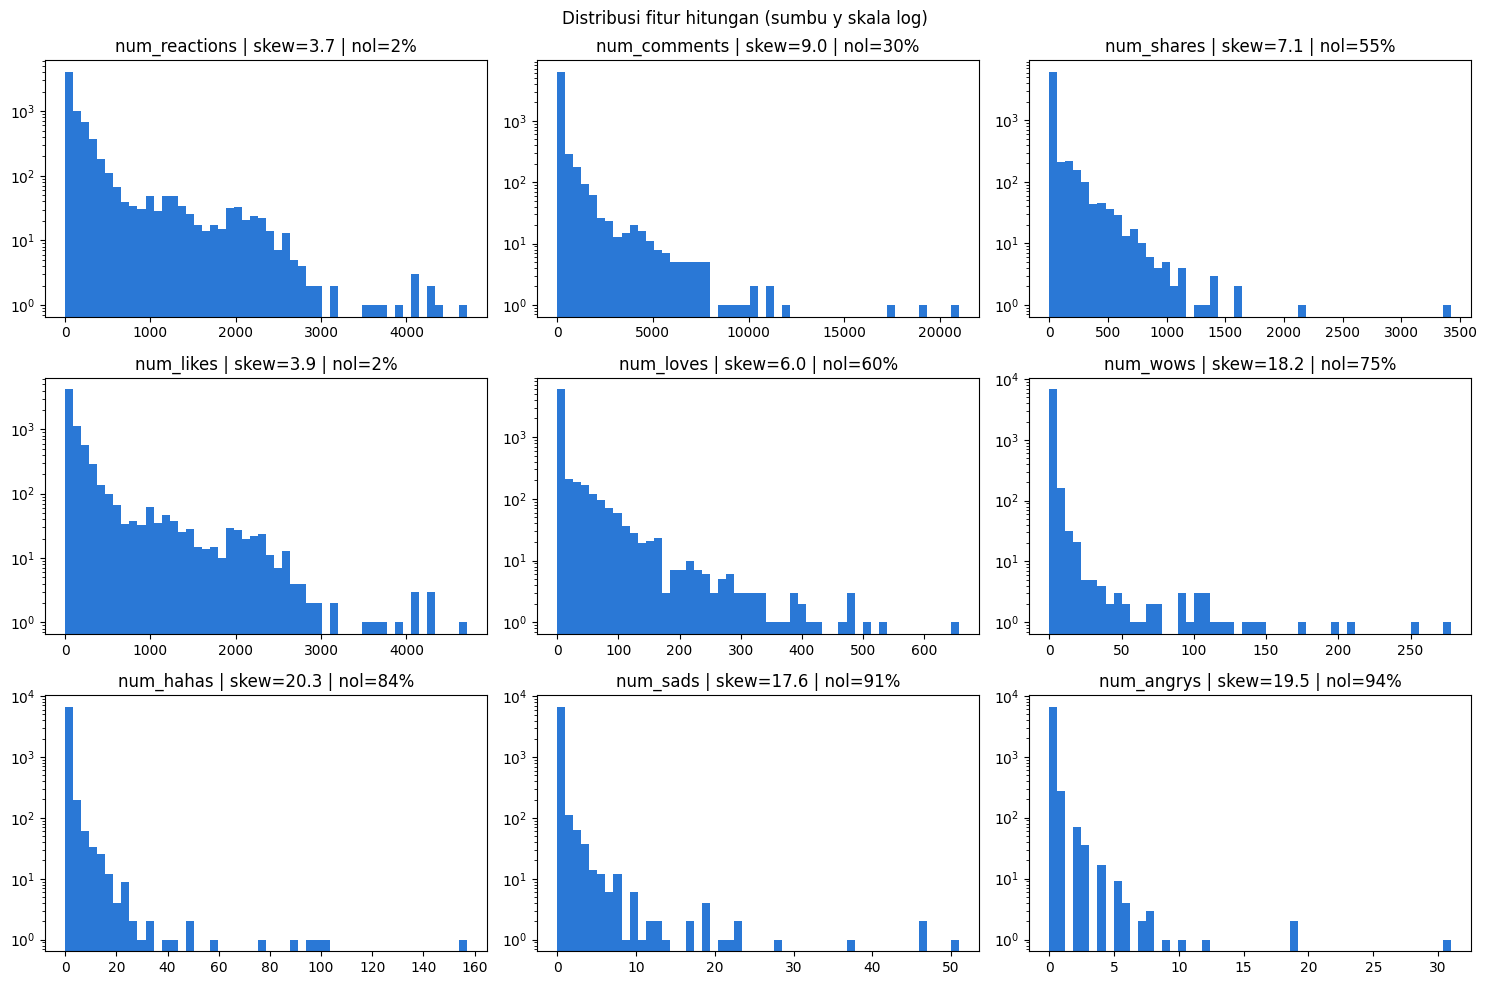

,mean,max,std,skew,proporsi_nol
num_reactions,230.1,4710,462.6,3.74,0.017
num_comments,224.4,20990,889.6,9.03,0.301
num_shares,40.0,3424,131.6,7.10,0.555
num_likes,215.0,4710,449.5,3.92,0.018
num_loves,12.7,657,40.0,6.00,0.600
num_wows,1.3,278,8.7,18.25,0.753
num_hahas,0.7,157,4.0,20.31,0.839
num_sads,0.2,51,1.6,17.58,0.914
num_angrys,0.1,31,0.7,19.51,0.940


In [4]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
num_cols = [c for c in df.columns if c.startswith('num_')]

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), num_cols):
    ax.hist(df[c], bins=50, color=COLORS[0])
    ax.set_yscale('log')  # sumbu y log agar ekor distribusi terlihat
    ax.set_title(f'{c} | skew={df[c].skew():.1f} | nol={(df[c] == 0).mean():.0%}')
fig.suptitle('Distribusi fitur hitungan (sumbu y skala log)')
plt.tight_layout(); plt.show()

pd.DataFrame({'mean': df[num_cols].mean().round(1), 'max': df[num_cols].max(),
              'std': df[num_cols].std().round(1), 'skew': df[num_cols].skew().round(2),
              'proporsi_nol': (df[num_cols] == 0).mean().round(3)})

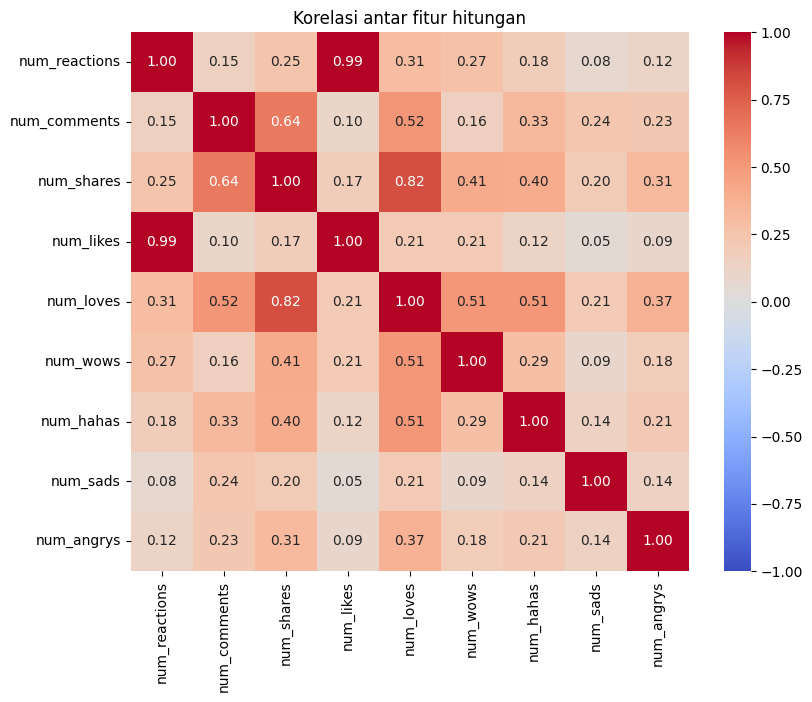

In [5]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.title('Korelasi antar fitur hitungan')
plt.show()

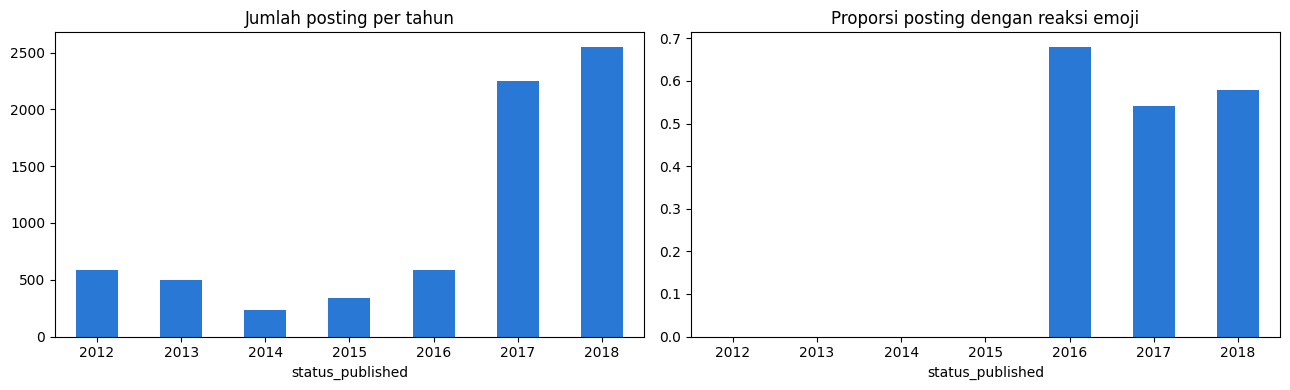

,jumlah_posting,proporsi_ada_emoji
status_published,,
2012,589,0.000
2013,500,0.000
2014,233,0.000
2015,337,0.000
2016,588,0.680
2017,2253,0.542
2018,2550,0.578


In [6]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published'] = pd.to_datetime(df['status_published'], format='%m/%d/%Y %H:%M')
emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
tahun = df['status_published'].dt.year
ada_emoji = df[emoji_cols].sum(axis=1) > 0

per_tahun = pd.DataFrame({'jumlah_posting': tahun.value_counts().sort_index(),
                          'proporsi_ada_emoji': ada_emoji.groupby(tahun).mean().round(3)})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
per_tahun['jumlah_posting'].plot(kind='bar', ax=axes[0], color=COLORS[0], title='Jumlah posting per tahun')
per_tahun['proporsi_ada_emoji'].plot(kind='bar', ax=axes[1], color=COLORS[0], title='Proporsi posting dengan reaksi emoji')
for ax in axes: ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
per_tahun

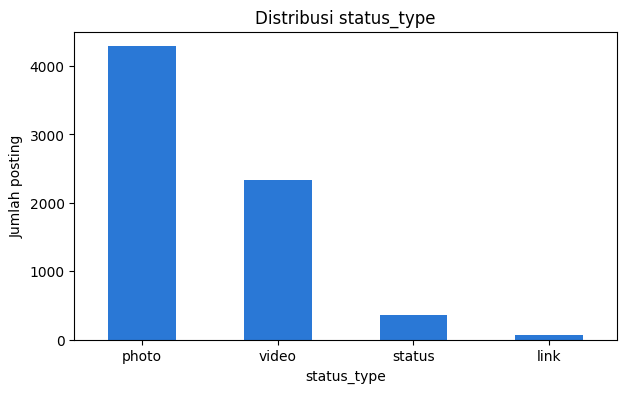

,num_likes,num_comments,num_shares
status_type,,,
link,48.0,1.0,0.0
photo,34.0,2.0,0.0
status,117.0,10.0,0.0
video,117.0,39.0,12.0


In [7]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
df['status_type'].value_counts().plot(kind='bar', color=COLORS[0], figsize=(7, 4), title='Distribusi status_type')
plt.ylabel('Jumlah posting'); plt.xticks(rotation=0); plt.show()

df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [8]:
# Cek apakah num_reactions adalah penjumlahan num_likes dan semua reaksi emoji
selisih = df['num_reactions'] - df[['num_likes'] + emoji_cols].sum(axis=1)
print('Proporsi baris dengan num_reactions = likes + emoji:', round((selisih == 0).mean(), 4))
print('Selisih maksimum:', selisih.max())

# Median engagement per tahun
df.groupby(tahun)[['num_likes', 'num_comments', 'num_shares', 'num_loves']].median()

Proporsi baris dengan num_reactions = likes + emoji: 0.9987
Selisih maksimum: 4


,num_likes,num_comments,num_shares,num_loves
status_published,,,,
2012,19.0,5.0,0.0,0.0
2013,55.0,3.0,0.0,0.0
2014,437.0,10.0,1.0,0.0
2015,1566.0,12.0,1.0,0.0
2016,139.0,6.0,0.0,1.0
2017,41.0,3.0,0.0,0.0
2018,54.5,2.5,1.0,1.0


# 2. Preprocessing

In [9]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
df = df.drop(columns=['Column1', 'Column2', 'Column3', 'Column4'])

# status_id selalu unik, jadi duplikat dicek tanpa status_id (posting yang sama terambil dua kali)
dup = df.drop(columns='status_id').duplicated()
print('Baris duplikat yang dihapus:', dup.sum())
df = df[~dup].reset_index(drop=True)
print('Missing value tersisa:', df.isna().sum().sum())

# Outlier ekstrem: nilai di atas Q3 + 3 * IQR
main_cols = ['num_reactions', 'num_comments', 'num_shares', 'num_likes']
q1, q3 = df[main_cols].quantile(0.25), df[main_cols].quantile(0.75)
print('\nJumlah outlier ekstrem per fitur:')
print((df[main_cols] > q3 + 3 * (q3 - q1)).sum())
# Outlier TIDAK dihapus: ini posting viral yang nyata. Pengaruhnya dikurangi dengan transformasi log1p.
print('\nUkuran data setelah dibersihkan:', df.shape)

Baris duplikat yang dihapus: 54
Missing value tersisa: 0

Jumlah outlier ekstrem per fitur:
num_reactions     510
num_comments     1245
num_shares       1237
num_likes         540
dtype: int64

Ukuran data setelah dibersihkan: (6996, 12)


In [10]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
info = df[['status_type', 'status_published']].copy()  # hanya untuk interpretasi

# num_reactions = num_likes + semua emoji -> redundan
print('Korelasi num_reactions vs num_likes:', round(df['num_reactions'].corr(df['num_likes']), 3))
print('Proporsi nol tiap kolom emoji:')
print((df[emoji_cols] == 0).mean().round(3))

# Gabungkan 5 kolom emoji yang sparse menjadi satu fitur
df['num_emoji'] = df[emoji_cols].sum(axis=1)
print('\nProporsi nol num_emoji:', round((df['num_emoji'] == 0).mean(), 3))

features = ['num_likes', 'num_comments', 'num_shares', 'num_emoji']
X_df = df[features]
X_df.describe()

Korelasi num_reactions vs num_likes: 0.995
Proporsi nol tiap kolom emoji:
num_loves     0.604
num_wows      0.757
num_hahas     0.840
num_sads      0.915
num_angrys    0.940
dtype: float64

Proporsi nol num_emoji: 0.565


,num_likes,num_comments,num_shares,num_emoji
count,6996.000000,6996.000000,6996.000000,6996.000000
mean,210.036735,225.648799,40.275872,15.051601
std,439.623067,892.922206,132.072584,47.953856
min,0.000000,0.000000,0.000000,0.000000
25%,17.000000,0.000000,0.000000,0.000000
50%,57.000000,4.000000,0.000000,0.000000
75%,182.000000,22.250000,4.000000,5.000000
max,4710.000000,20990.000000,3424.000000,886.000000


**Fitur yang dipilih untuk clustering:** `num_likes`, `num_comments`, `num_shares`, dan `num_emoji` (fitur baru).
- `num_reactions` dibuang karena redundan: nilainya = `num_likes` + semua emoji (cocok di 99,9% baris, korelasi dengan `num_likes` 0,995). Jika tetap dipakai, informasi like terhitung dua kali.
- Lima kolom emoji (`num_loves`, `num_wows`, `num_hahas`, `num_sads`, `num_angrys`) sebagian besar bernilai nol (60-94%). Kelimanya digabung menjadi `num_emoji` agar tidak ada banyak fitur yang isinya hampir semua nol.
- `status_id` dibuang karena hanya ID. `status_type` dan `status_published` tidak dipakai sebagai fitur, hanya untuk interpretasi.

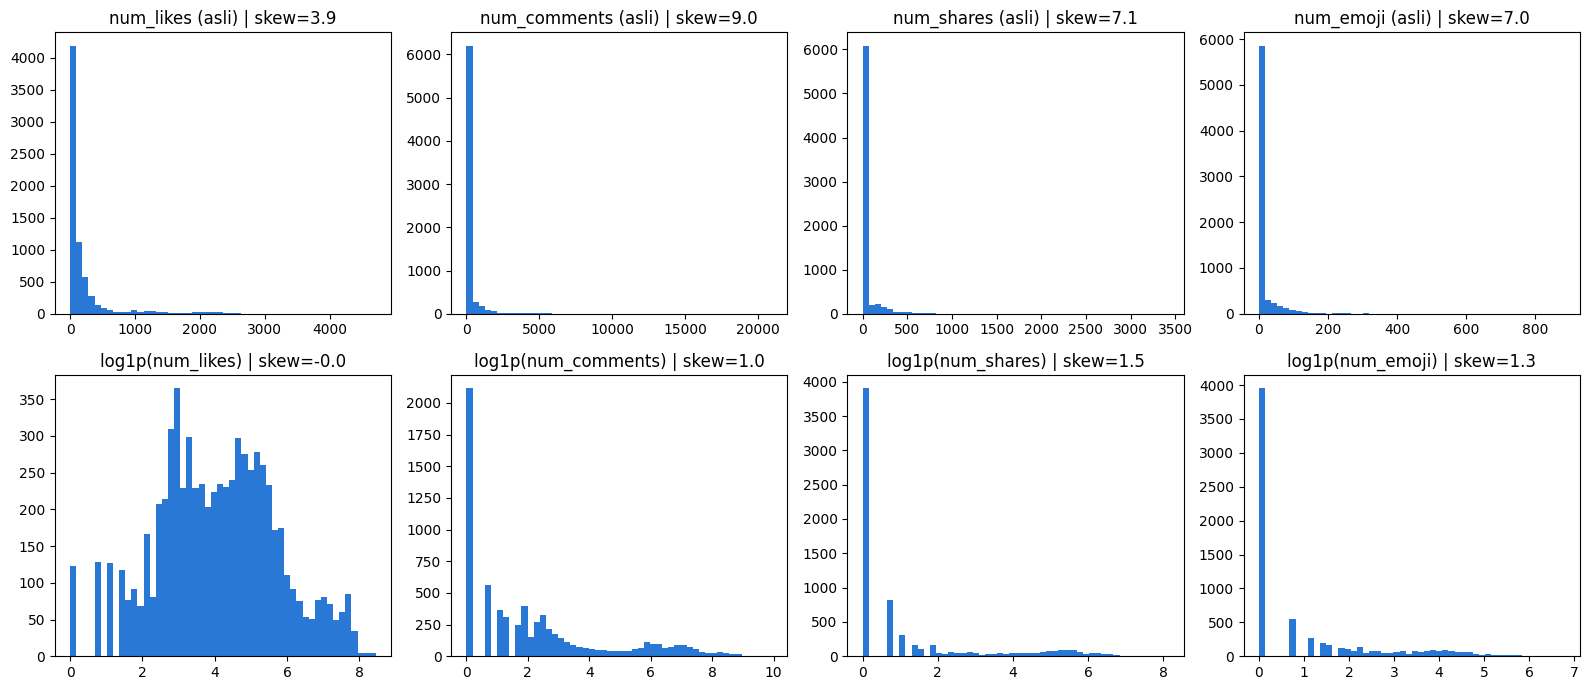

In [11]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X_df)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, c in enumerate(features):
    axes[0, i].hist(X_df[c], bins=50, color=COLORS[0])
    axes[0, i].set_title(f'{c} (asli) | skew={X_df[c].skew():.1f}')
    axes[1, i].hist(X_log[c], bins=50, color=COLORS[0])
    axes[1, i].set_title(f'log1p({c}) | skew={X_log[c].skew():.1f}')
plt.tight_layout(); plt.show()

In [12]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
X_raw = X_df.values
X_raw_scaled = StandardScaler().fit_transform(X_raw)
X_log_scaled = StandardScaler().fit_transform(X_log)
print('X_raw:', X_raw.shape, '| X_raw_scaled:', X_raw_scaled.shape, '| X_log_scaled:', X_log_scaled.shape)

X_raw: (6996, 4) | X_raw_scaled: (6996, 4) | X_log_scaled: (6996, 4)


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [13]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
versi_data = {'X_raw': X_raw, 'X_raw_scaled': X_raw_scaled, 'X_log_scaled': X_log_scaled}
labels_versi = {nama: KMeans(n_clusters=3, n_init=10, random_state=RS).fit_predict(data)
                for nama, data in versi_data.items()}

In [14]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
print('Proporsi varians tiap fitur pada data mentah:')
print((X_df.var() / X_df.var().sum()).round(3))

pd.DataFrame({nama: {'ukuran cluster': sorted(np.bincount(l), reverse=True),
                     'cluster terbesar (%)': round(np.bincount(l).max() / len(l) * 100, 1),
                     'silhouette (X_log_scaled)': round(silhouette_score(X_log_scaled, l), 4)}
              for nama, l in labels_versi.items()}).T

Proporsi varians tiap fitur pada data mentah:
num_likes       0.191
num_comments    0.789
num_shares      0.017
num_emoji       0.002
dtype: float64


,ukuran cluster,cluster terbesar (%),silhouette (X_log_scaled)
X_raw,"[6392, 467, 137]",91.4,0.2731
X_raw_scaled,"[6277, 373, 346]",89.7,0.2533
X_log_scaled,"[3607, 2258, 1131]",51.6,0.4638


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [15]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
k_range = list(range(2, 11))
inertias, km_labels = [], {}
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X_log_scaled)
    inertias.append(km.inertia_)
    km_labels[k] = km.labels_

elbow_df = pd.DataFrame({'k': k_range, 'inertia': np.round(inertias, 1)})
elbow_df['penurunan (%)'] = (-elbow_df['inertia'].pct_change() * 100).round(1)
elbow_df

,k,inertia,penurunan (%)
0,2,11586.9,NaN
1,3,6779.8,41.5
2,4,5678.3,16.2
3,5,4740.0,16.5
4,6,4220.3,11.0
5,7,3772.1,10.6
6,8,3418.6,9.4
7,9,3116.4,8.8
8,10,2899.1,7.0


Elbow otomatis (jarak terjauh dari garis): 4


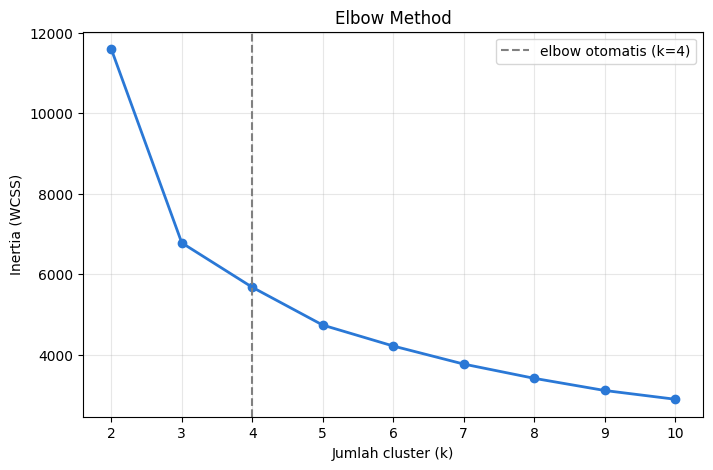

In [16]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.

# kneed tidak terpasang, jadi elbow dicari dengan cara yang sama seperti KneeLocator:
# titik dengan jarak terjauh dari garis lurus yang menghubungkan k pertama dan k terakhir
k_arr, y = np.array(k_range), np.array(inertias)
x_n = (k_arr - k_arr.min()) / (k_arr.max() - k_arr.min())
y_n = (y - y.min()) / (y.max() - y.min())
elbow_k = k_arr[np.argmax((1 - x_n) - y_n)]
print('Elbow otomatis (jarak terjauh dari garis):', elbow_k)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker='o', color=COLORS[0], linewidth=2)
plt.axvline(elbow_k, color='grey', ls='--', label=f'elbow otomatis (k={elbow_k})')
plt.xlabel('Jumlah cluster (k)'); plt.ylabel('Inertia (WCSS)'); plt.title('Elbow Method')
plt.xticks(k_range); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [17]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
sil_scores = {k: silhouette_score(X_log_scaled, km_labels[k]) for k in k_range}
pd.Series(sil_scores, name='silhouette').round(4).to_frame()

,silhouette
2,0.5899
3,0.4638
4,0.3372
5,0.3586
6,0.3469
7,0.3367
8,0.3154
9,0.3293
10,0.3160


k dengan Silhouette tertinggi: 2


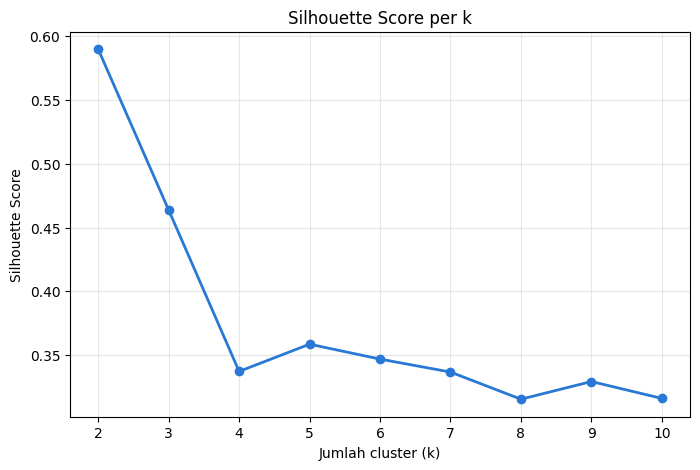

In [18]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
best_sil_k = max(sil_scores, key=sil_scores.get)
print('k dengan Silhouette tertinggi:', best_sil_k)

plt.figure(figsize=(8, 5))
plt.plot(k_range, list(sil_scores.values()), marker='o', color=COLORS[0], linewidth=2)
plt.xlabel('Jumlah cluster (k)'); plt.ylabel('Silhouette Score'); plt.title('Silhouette Score per k')
plt.xticks(k_range); plt.grid(alpha=0.3); plt.show()

**Pilihan k untuk K-Means:** k = 3.
- Elbow: inertia turun paling besar dari k=2 ke k=3 (41,5%), setelah itu hanya sekitar 16% lalu makin kecil. Jadi siku ada di k=3. Deteksi otomatis memilih k=4, tetapi selisih k=3 dan k=4 di grafik sangat tipis.
- Silhouette: tertinggi di k=2 (0,590), lalu k=3 (0,464). Setelah k=3 nilainya turun ke sekitar 0,34 atau kurang.
- k=3 dipilih karena menjadi titik siku dan Silhouette-nya masih tinggi. k=2 hanya memisahkan "video ramai" dan "sisanya", sedangkan k=3 juga memisahkan posting sepi dan posting yang banyak like, sehingga lebih berguna untuk interpretasi.

## 3.4 Model K-Means Final

In [19]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
K_FINAL = 3

def urutkan_label(labels):
    # Ubah nomor cluster agar urut dari engagement terendah (0) ke tertinggi
    urutan = pd.Series(X_log_scaled.sum(axis=1)).groupby(labels).mean().sort_values().index
    return pd.Series(labels).map({lama: baru for baru, lama in enumerate(urutan)}).values

t0 = time.time()
kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RS).fit(X_log_scaled)
waktu_km = time.time() - t0
labels_km = urutkan_label(kmeans.labels_)
print(f'Waktu training K-Means: {waktu_km:.2f} detik')
print('Jumlah anggota tiap cluster:', np.bincount(labels_km))

Waktu training K-Means: 0.03 detik
Jumlah anggota tiap cluster: [3607 2258 1131]


In [20]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
def profil_cluster(labels):
    data = X_df.assign(cluster=labels)
    prof = data.groupby('cluster')[features].agg(['median', 'mean']).round(1)
    prof['jumlah_anggota'] = data['cluster'].value_counts().sort_index()
    return prof

profil_cluster(labels_km)

num_likes        num_comments         num_shares        num_emoji  \
           median   mean       median    mean     median   mean    median   
cluster                                                                     
0            18.0   22.2          0.0     2.1        0.0    0.5       0.0   
1           206.0  462.7         11.0    26.9        1.0    4.7       2.0   
2           170.0  304.5        722.0  1335.4      178.0  238.0      57.0   

              jumlah_anggota  
         mean                 
cluster                       
0         0.2           3607  
1         4.6           2258  
2        83.3           1131

# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [21]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
t0 = time.time()
Z = linkage(X_log_scaled, method='ward')
print(f'Waktu hitung linkage matrix: {time.time() - t0:.2f} detik')
print('Ukuran linkage matrix:', Z.shape)

Waktu hitung linkage matrix: 0.37 detik
Ukuran linkage matrix: (6995, 4)


Tinggi 6 penggabungan terakhir: [ 27.5  37.5  42.3  48.4 103.7 175.1]


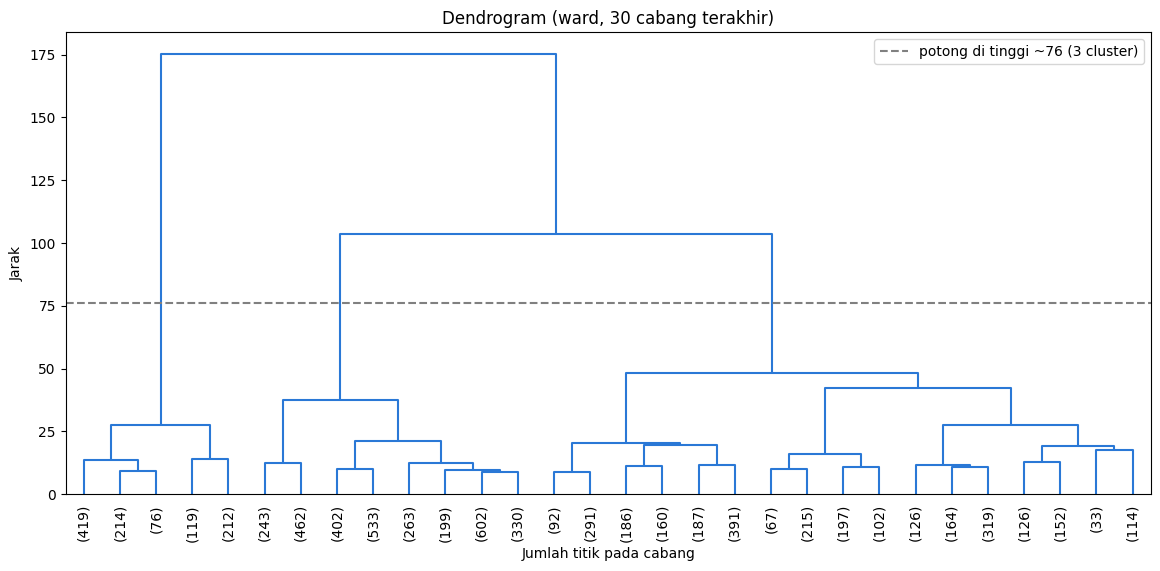

In [22]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
print('Tinggi 6 penggabungan terakhir:', Z[-6:, 2].round(1))
cut = (Z[-3, 2] + Z[-2, 2]) / 2  # garis potong di antara penggabungan ke-3 dan ke-2 terakhir -> 3 cluster

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, link_color_func=lambda k: COLORS[0])
plt.axhline(cut, color='grey', ls='--', label=f'potong di tinggi ~{cut:.0f} (3 cluster)')
plt.title('Dendrogram (ward, 30 cabang terakhir)'); plt.xlabel('Jumlah titik pada cabang'); plt.ylabel('Jarak')
plt.legend(); plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [23]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
linkages = ['ward', 'complete', 'average', 'single']
labels_link = {}
for m in linkages:
    t0 = time.time()
    labels_link[m] = AgglomerativeClustering(n_clusters=K_FINAL, linkage=m).fit_predict(X_log_scaled)
    print(f'{m}: {time.time() - t0:.2f} detik')

ward: 0.35 detik


complete: 0.33 detik


average: 0.35 detik
single: 0.08 detik


In [24]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
pd.DataFrame({m: {'silhouette': round(silhouette_score(X_log_scaled, l), 4),
                  'ukuran cluster': sorted(np.bincount(l), reverse=True),
                  'cluster terbesar (%)': round(np.bincount(l).max() / len(l) * 100, 1),
                  'cluster terkecil': np.bincount(l).min()}
              for m, l in labels_link.items()}).T

,silhouette,ukuran cluster,cluster terbesar (%),cluster terkecil
ward,0.4201,"[3034, 2922, 1040]",43.4,1040
complete,0.1163,"[5775, 761, 460]",82.5,460
average,0.5069,"[5764, 1197, 35]",82.4,35
single,0.3139,"[6994, 1, 1]",100.0,1


**Pilihan linkage untuk Hierarchical Clustering:** ward.
- Ward menghasilkan cluster yang seimbang (3034, 2922, 1040) dengan Silhouette 0,420.
- Average punya Silhouette tertinggi (0,507), tetapi 82% data masuk satu cluster dan satu cluster hanya berisi 35 posting. Nilai tinggi itu muncul karena outlier dipisahkan sendiri, bukan karena kelompoknya berguna.
- Complete juga tidak seimbang (82,5% di satu cluster) dan Silhouette-nya paling rendah (0,116).
- Single gagal: 6994 posting di satu cluster, dua cluster lainnya hanya berisi 1 posting.

## 4.3 Model Hierarchical Clustering Final

In [25]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
t0 = time.time()
hc = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward').fit(X_log_scaled)
waktu_hc = time.time() - t0
labels_hc = urutkan_label(hc.labels_)
print(f'Waktu training Hierarchical Clustering: {waktu_hc:.2f} detik')
print('Jumlah anggota tiap cluster:', np.bincount(labels_hc))

Waktu training Hierarchical Clustering: 0.35 detik
Jumlah anggota tiap cluster: [3034 2922 1040]


In [26]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
profil_cluster(labels_hc)

num_likes        num_comments         num_shares        num_emoji  \
           median   mean       median    mean     median   mean    median   
cluster                                                                     
0            14.0   16.7          0.0     1.8        0.0    0.2       0.0   
1           150.0  386.8          9.0    29.4        1.0    5.3       1.0   
2           168.0  277.5        815.5  1430.2      193.5  255.4      60.5   

              jumlah_anggota  
         mean                 
cluster                       
0         0.1           3034  
1         4.5           2922  
2        88.2           1040

# 5. Evaluasi Model

In [27]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
hasil = {'K-Means': labels_km, 'Hierarchical (ward)': labels_hc}
metrik = pd.DataFrame({nama: {'Silhouette': silhouette_score(X_log_scaled, l),
                              'Davies-Bouldin': davies_bouldin_score(X_log_scaled, l),
                              'Calinski-Harabasz': calinski_harabasz_score(X_log_scaled, l)}
                       for nama, l in hasil.items()}).T.round(4)
metrik['Waktu training (detik)'] = [round(waktu_km, 2), round(waktu_hc, 2)]
display(metrik)

# Seberapa mirip label kedua metode (1 = identik, 0 = acak)
print('Adjusted Rand Index K-Means vs Hierarchical:', round(adjusted_rand_score(labels_km, labels_hc), 3))
pd.crosstab(labels_km, labels_hc, rownames=['K-Means'], colnames=['Hierarchical'])

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Waktu training (detik)
K-Means,0.4638,0.8302,10935.4612,0.03
Hierarchical (ward),0.4201,0.8329,9959.1882,0.35


Adjusted Rand Index K-Means vs Hierarchical: 0.707


Hierarchical,0,1,2
K-Means,,,
0,3031,576,0
1,3,2255,0
2,0,91,1040


Varians dijelaskan: PC1 = 75.9%, PC2 = 16.0%, total = 91.8%


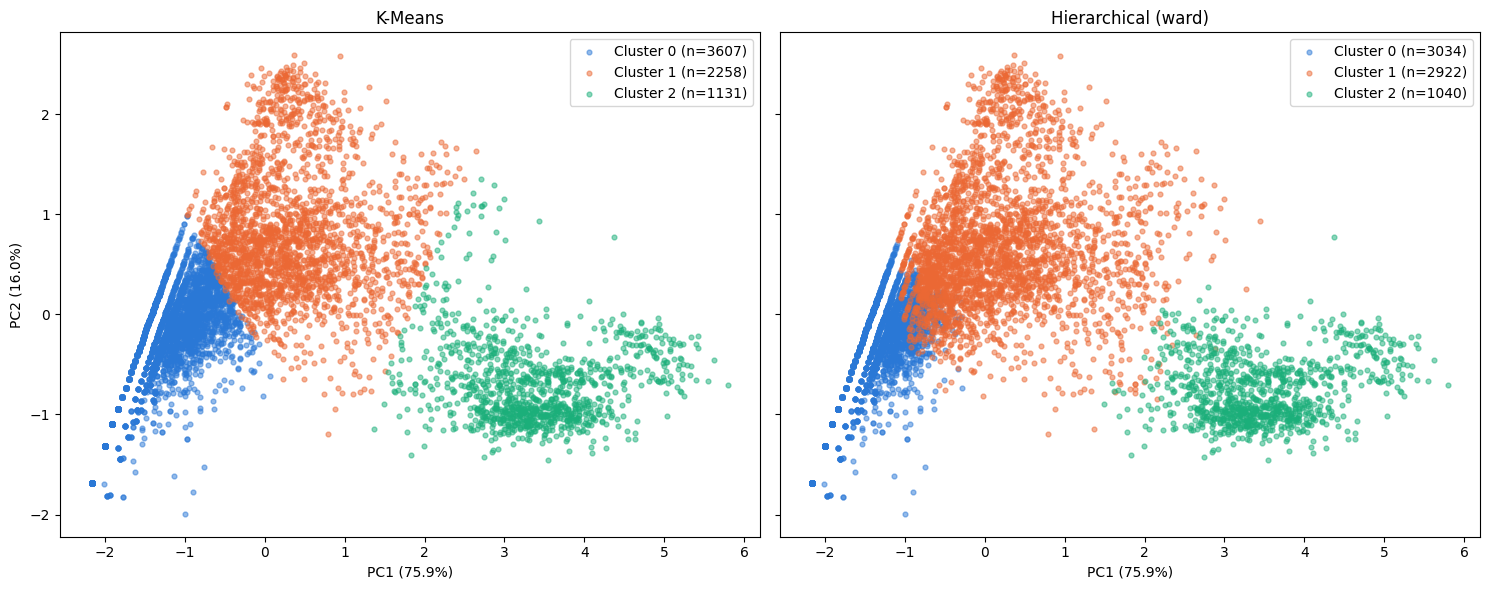

In [28]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2, random_state=RS)
X_pca = pca.fit_transform(X_log_scaled)
var = pca.explained_variance_ratio_
print(f'Varians dijelaskan: PC1 = {var[0]:.1%}, PC2 = {var[1]:.1%}, total = {var.sum():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, (nama, l) in zip(axes, hasil.items()):
    for c in range(K_FINAL):
        m = l == c
        ax.scatter(X_pca[m, 0], X_pca[m, 1], s=12, alpha=0.5, color=COLORS[c], label=f'Cluster {c} (n={m.sum()})')
    ax.set_title(nama); ax.set_xlabel(f'PC1 ({var[0]:.1%})'); ax.legend()
axes[0].set_ylabel(f'PC2 ({var[1]:.1%})')
plt.tight_layout(); plt.show()

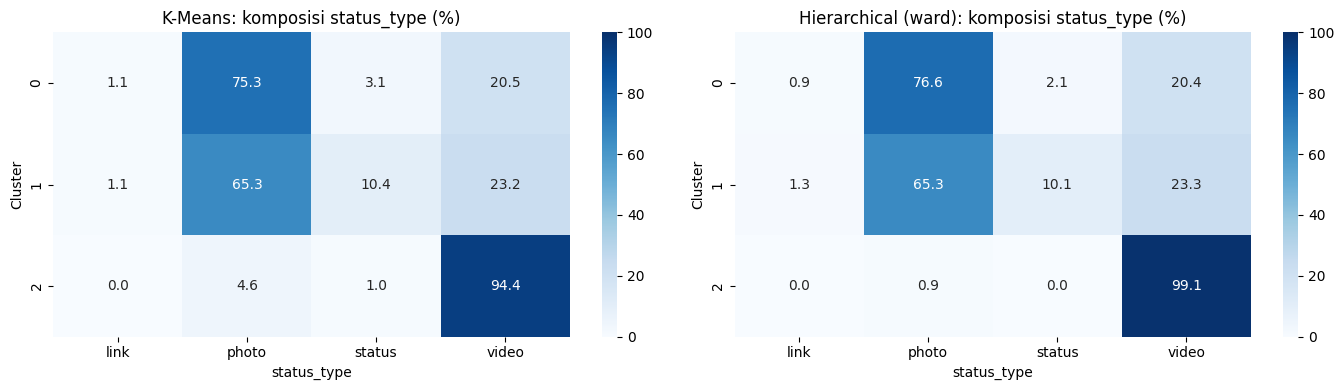

,K-Means (% sebelum 2016),Hierarchical (ward) (% sebelum 2016)
Cluster,,
0,26.2,25.3
1,31.6,30.5
2,0.0,0.0


In [29]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (nama, l) in zip(axes, hasil.items()):
    ct = pd.crosstab(l, info['status_type'], normalize='index') * 100
    sns.heatmap(ct, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100, ax=ax)
    ax.set_title(f'{nama}: komposisi status_type (%)'); ax.set_ylabel('Cluster')
plt.tight_layout(); plt.show()

# Tambahan: proporsi posting sebelum 2016 (belum ada reaksi emoji) di tiap cluster
sebelum_2016 = info['status_published'].dt.year < 2016
pd.DataFrame({nama: (sebelum_2016.groupby(l).mean() * 100).round(1) for nama, l in hasil.items()}) \
  .rename_axis('Cluster').add_suffix(' (% sebelum 2016)')

# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.


**1. Pengaruh transformasi log dan scaling**
- Tanpa scaling, `num_comments` menguasai 79% varians, sehingga K-Means hampir hanya melihat jumlah komentar. Akibatnya 91% data masuk satu cluster.
- Scaling saja belum cukup. Data masih sangat miring, jadi posting viral menarik centroid dan sekitar 90% data tetap masuk satu cluster.
- Setelah log1p + scaling, cluster jadi seimbang (3607, 2258, 1131) dan Silhouette naik dari sekitar 0,26 ke 0,464.
- Keduanya penting karena K-Means memakai jarak. Log mengecilkan efek outlier, scaling menyamakan bobot tiap fitur.

**2. Kolom redundan dan banyak nol**
- `num_reactions` dibuang karena nilainya sama dengan likes + emoji.
- Lima kolom emoji (60-94% nol) digabung menjadi satu fitur `num_emoji`.
- Kolom kosong dan 54 baris duplikat dihapus. Outlier tidak dihapus karena itu posting viral yang nyata; efeknya dikurangi dengan log1p.

**3. Jumlah cluster optimal**
- Elbow menunjukkan siku di k=3, sedangkan Silhouette tertinggi di k=2 (0,590), lalu k=3 (0,464).
- Saya memilih k=3 karena menjadi titik siku, Silhouette-nya masih tinggi, dan cluster-nya lebih mudah ditafsirkan. Dendrogram juga mendukung 3 cluster.

**4. Perbandingan linkage**
- Ward paling baik karena cluster-nya seimbang (Silhouette 0,420).
- Average punya Silhouette tertinggi (0,507), tetapi satu cluster hanya berisi 35 outlier. Complete juga tidak seimbang dan Silhouette-nya paling rendah (0,116).
- Single linkage mengalami efek *chaining*: titik-titik saling menyambung menjadi satu rantai, sehingga 6994 posting masuk satu cluster dan dua cluster lainnya hanya berisi 1 posting.

**5. K-Means vs Hierarchical Clustering**
- K-Means sedikit lebih baik di semua metrik (Silhouette 0,464 vs 0,420; Davies-Bouldin 0,830 vs 0,833; Calinski-Harabasz 10935 vs 9959), tetapi bedanya kecil.
- Plot PCA kedua metode hampir sama (ARI 0,707). Ini wajar karena ward dan K-Means sama-sama meminimalkan varians di dalam cluster.

**6. Karakteristik cluster**
- **Cluster 0 - Posting Sepi** (3607 posting): hampir tidak ada interaksi (median 18 like, 0 komentar). Mayoritas foto.
- **Cluster 1 - Posting Disukai** (2258 posting): banyak like (median 206), tetapi jarang dikomentari atau dibagikan.
- **Cluster 2 - Video Interaktif** (1131 posting): komentar dan share sangat tinggi (median 722 komentar, 178 share). 94% video, kemungkinan sesi live jualan.

**7. Kelebihan dan kekurangan**
- **K-Means**: cepat dan hemat memori, tetapi k harus ditentukan di awal dan cocok untuk cluster berbentuk bulat.
- **Hierarchical**: k tidak perlu ditentukan di awal (bisa dipilih dari dendrogram), tetapi lebih lambat dan butuh memori besar untuk data yang banyak.

# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.



**Kesimpulan**
- Posting Facebook penjual terbagi menjadi 3 kelompok: **Posting Sepi** (51,6%), **Posting Disukai** (32,3%), dan **Video Interaktif** (16,2%).
- Video adalah jenis posting dengan interaksi tertinggi (komentar dan share), sedangkan foto mendominasi posting dengan interaksi rendah.
- Transformasi log1p dan scaling wajib untuk data ini. Tanpa keduanya, sekitar 90% data masuk satu cluster dan Silhouette hanya 0,25-0,27.
- K-Means (Silhouette 0,464) sedikit lebih baik dan lebih cepat daripada Hierarchical ward (0,420). Hasil keduanya mirip (ARI 0,707).
- Untuk Hierarchical Clustering, ward adalah linkage terbaik. Single linkage gagal karena efek chaining.

**Saran**
- Lakukan clustering terpisah untuk posting sebelum dan sesudah 2016, karena reaksi emoji baru ada sejak 2016 dan semua posting lama otomatis bernilai nol di `num_emoji`.
- Tambahkan fitur waktu (jam atau hari posting) untuk melihat kapan posting paling ramai.
- Coba DBSCAN untuk memisahkan posting viral (outlier) secara otomatis, atau Gaussian Mixture Model untuk cluster yang bentuknya tidak bulat.
- Coba variasi `n_init` dan `init` pada K-Means untuk memastikan hasil cluster stabil.